# HIT140 — Linear Regression 2.2: Team Goals Scored

**Objective:** Predict goals scored by an individual team in a FIFA World Cup 2026 match.

- 104 matches are transformed in Python into **208 team–match observations**, with two teams per match.
- **Target (Y):** `goals_scored`.
- **Predictors (exactly 8):**

| Number | Predictor | Description |
|---|---|---|
| X1 | `team_fifa_rank` | Team's pre-match FIFA ranking |
| X2 | `team_elo_rating_before` | Team's pre-match Elo rating |
| X3 | `team_last5_avg_goals_scored` | Recent five-match goals-scored average |
| X4 | `team_last5_win_rate` | Recent five-match win rate |
| X5 | `is_knockout` | 1 for a knockout match, otherwise 0 |
| X6 | `is_host_nation` | 1 if team is a 2026 host nation |
| X7 | `wc_matches_played_before` | World Cup matches previously played by the team |
| X8 | `wc_goals_conceded_before` | World Cup goals previously conceded by the team |

**Shared with Task 2.1:** four underlying concepts (X1–X4), used here at the team level rather than as team differences. **New predictors:** X5–X8.

**Data:** `data/Source_104_Matches.xlsx` is the source workbook. The code reads three worksheets (`Master_104_Matches`, `X1_X2_Inputs`, and `X3_X5_Detail`); the remaining worksheets document source preparation and evidence. **All joining, feature creation, model training and analysis occur in Python.**



## 1. Python imports and file paths

In [1]:
from pathlib import Path
from collections import defaultdict
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from joblib import dump, load

DATA_FILE = Path("data/Source_104_Matches.xlsx")
OUT = Path("outputs")
OUT.mkdir(exist_ok=True)
DATASET_FILE = Path("data/Regression_2_2_208_Team_Rows.csv")
FEATURES = [
    "team_fifa_rank", "team_elo_rating_before", "team_last5_avg_goals_scored",
    "team_last5_win_rate", "is_knockout", "is_host_nation",
    "wc_matches_played_before", "wc_goals_conceded_before"
]
TARGET = "goals_scored"
assert DATA_FILE.exists(), f"Put {DATA_FILE.name} beside this notebook/script."
print("Source file found:", DATA_FILE.name)


Source file found: Source_104_Matches.xlsx


## 2. Read original Excel sheets in Python

In [2]:
# Excel is only the original data source. Joins, wrangling and analyses all happen here in Python.
master = pd.read_excel(DATA_FILE, sheet_name="Master_104_Matches")
ratings = pd.read_excel(DATA_FILE, sheet_name="X1_X2_Inputs")
form = pd.read_excel(DATA_FILE, sheet_name="X3_X5_Detail")
assert len(master) == len(ratings) == len(form) == 104
assert master["match_id"].is_unique
assert master["team_a_goals"].notna().all() and master["team_b_goals"].notna().all()

# Workbooks sometimes provide Excel dates as serial numbers, and sometimes as actual dates.
if pd.api.types.is_numeric_dtype(master["match_date"]):
    master["match_date"] = pd.to_datetime(master["match_date"], unit="D", origin="1899-12-30")
else:
    master["match_date"] = pd.to_datetime(master["match_date"])

cols_r = ["match_id","team_a","team_b","fifa_rank_a","fifa_rank_b","elo_a_before","elo_b_before"]
cols_f = ["match_id","team_a","team_b","team_a_last5_avg_goals","team_b_last5_avg_goals",
          "team_a_last5_win_rate","team_b_last5_win_rate"]
source = master.merge(ratings[cols_r], on=["match_id","team_a","team_b"], validate="one_to_one")
source = source.merge(form[cols_f], on=["match_id","team_a","team_b"], validate="one_to_one")
assert len(source) == 104

# Check that team-level inputs reproduce the difference variables used in 2.1.
checks = {
    "FIFA rank": (source["fifa_rank_a"] - source["fifa_rank_b"], source["fifa_rank_diff"]),
    "Elo": (source["elo_a_before"] - source["elo_b_before"], source["elo_rating_diff"]),
    "Last-5 goals scored": (source["team_a_last5_avg_goals"] - source["team_b_last5_avg_goals"], source["last5_avg_goals_scored_diff"]),
    "Last-5 win rate": (source["team_a_last5_win_rate"] - source["team_b_last5_win_rate"], source["last5_win_rate_diff"]),
}
for label, (left, right) in checks.items():
    assert np.allclose(left.to_numpy(dtype=float), right.to_numpy(dtype=float), atol=1e-6), f"Mismatch in {label}"

source = source.sort_values(["match_date", "match_id"]).reset_index(drop=True)
print("Validated input:", len(source), "World Cup matches, 48 teams expected, four reused concepts cross-checked")
print("Date range:", source["match_date"].min().date(), "to", source["match_date"].max().date())


Validated input: 104 World Cup matches, 48 teams expected, four reused concepts cross-checked
Date range: 2026-06-11 to 2026-07-19


## 3. Convert 104 matches into 208 team-match observations

In [3]:
# Only matches from STRICTLY EARLIER DATES contribute to cumulative World Cup features.
# Do not update the team's history until every match on the current date has been added.
history = defaultdict(lambda: {"matches": 0, "goals_conceded": 0})
records = []
host_nations = {"Mexico", "Canada", "USA"}
for match_date, daily_matches in source.groupby("match_date", sort=True):
    for m in daily_matches.itertuples(index=False):
        for side, team, opponent, goals, conceded, rank, elo, avg_scored, win_rate in (
            ("A", m.team_a, m.team_b, m.team_a_goals, m.team_b_goals,
             m.fifa_rank_a, m.elo_a_before, m.team_a_last5_avg_goals, m.team_a_last5_win_rate),
            ("B", m.team_b, m.team_a, m.team_b_goals, m.team_a_goals,
             m.fifa_rank_b, m.elo_b_before, m.team_b_last5_avg_goals, m.team_b_last5_win_rate),
        ):
            h = history[team]
            records.append({
                "match_id": int(m.match_id), "match_date": match_date,
                "team": team, "opponent": opponent, "side": side,
                "stage": m.stage, "team_fifa_rank": float(rank),
                "team_elo_rating_before": float(elo),
                "team_last5_avg_goals_scored": float(avg_scored),
                "team_last5_win_rate": float(win_rate),
                "is_knockout": int(m.stage != "Group Stage"),
                "is_host_nation": int(team in host_nations),
                "wc_matches_played_before": int(h["matches"]),
                "wc_goals_conceded_before": int(h["goals_conceded"]),
                "goals_scored": int(goals),
            })
    # Update histories AFTER collecting all predictions for today's matches.
    for m in daily_matches.itertuples(index=False):
        history[m.team_a]["matches"] += 1
        history[m.team_a]["goals_conceded"] += int(m.team_b_goals)
        history[m.team_b]["matches"] += 1
        history[m.team_b]["goals_conceded"] += int(m.team_a_goals)

team_data = pd.DataFrame.from_records(records).sort_values(["match_date","match_id","side"]).reset_index(drop=True)
assert len(team_data) == 208, "Exactly two rows per each of the 104 matches are required."
assert team_data["match_id"].nunique() == 104
assert (team_data.groupby("match_id").size() == 2).all()
assert not team_data.duplicated(["match_id", "team"]).any()
assert team_data[FEATURES + [TARGET]].notna().all().all()
assert (team_data["goals_scored"] >= 0).all()
assert set(team_data.loc[team_data["wc_matches_played_before"] == 0, "wc_goals_conceded_before"]) == {0}

print("Created", len(team_data), "team-match rows")
print("Predictors:", len(FEATURES), "(4 shared concepts + 4 new)")
display(team_data.head(6))


Created 208 team-match rows
Predictors: 8 (4 shared concepts + 4 new)


,match_id,match_date,team,opponent,side,stage,team_fifa_rank,team_elo_rating_before,team_last5_avg_goals_scored,team_last5_win_rate,is_knockout,is_host_nation,wc_matches_played_before,wc_goals_conceded_before,goals_scored
0,1,2026-06-11,Mexico,South Africa,A,Group Stage,14.0,1875.0,1.8,0.6,0,1,0,0,2
1,1,2026-06-11,South Africa,Mexico,B,Group Stage,60.0,1517.0,0.8,0.2,0,0,0,0,0
2,2,2026-06-11,Korea Republic,Czechia,A,Group Stage,25.0,1758.0,1.4,0.6,0,0,0,0,2
3,2,2026-06-11,Czechia,Korea Republic,B,Group Stage,40.0,1740.0,3.4,0.6,0,0,0,0,1
4,3,2026-06-12,Canada,Bosnia and Herzegovina,A,Group Stage,30.0,1788.0,1.4,0.4,0,1,0,0,1
5,3,2026-06-12,Bosnia and Herzegovina,Canada,B,Group Stage,64.0,1595.0,0.8,0.0,0,0,0,0,1


## 4. Chronological train/test split: keep both teams in the same partition

In [4]:
# Use a date boundary nearest to an 80/20 match split; never split two sides of a match.
match_dates = source["match_date"].drop_duplicates().sort_values()
expected_train_matches = int(len(source) * 0.80)
test_start = min(match_dates.iloc[1:], key=lambda dt: abs(int((source["match_date"] < dt).sum()) - expected_train_matches))
team_data["data_split"] = np.where(team_data["match_date"] < test_start, "train", "test")
train = team_data.loc[team_data["data_split"] == "train"].copy()
test = team_data.loc[team_data["data_split"] == "test"].copy()
assert set(train["match_id"]).isdisjoint(test["match_id"])
assert len(train) + len(test) == 208
assert train["match_date"].max() < test["match_date"].min()

X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print(f"Training: {len(train)} team rows ({train['match_id'].nunique()} matches)")
print(f"Testing: {len(test)} team rows ({test['match_id'].nunique()} matches)")
print("First test match date:", test_start.date())


Training: 164 team rows (82 matches)
Testing: 44 team rows (22 matches)
First test match date: 2026-07-02


## 5. Train multiple linear regression and inspect eight coefficients

In [5]:
model = LinearRegression(fit_intercept=True)
model.fit(X_train, y_train)
coefficients = pd.DataFrame({"variable": FEATURES, "coefficient": model.coef_})
intercept = float(model.intercept_)
print("Intercept:", round(intercept, 6))
display(coefficients.round(6))


Intercept: -1.110813


,variable,coefficient
0,team_fifa_rank,-0.015761
1,team_elo_rating_before,0.001858
2,team_last5_avg_goals_scored,0.034485
3,team_last5_win_rate,-0.628578
4,is_knockout,-0.421306
5,is_host_nation,0.743495
6,wc_matches_played_before,-0.029474
7,wc_goals_conceded_before,0.007506


## 6. Evaluate on completely held-out matches

In [6]:
# Model predictions are continuous and may be slightly negative; we do NOT clip them,
# because this is an ordinary linear regression assignment, not a count model.
team_data["predicted_goals"] = model.predict(team_data[FEATURES])
test_pred = model.predict(X_test)
train_pred = model.predict(X_train)

metrics = {
    "train_MAE": float(mean_absolute_error(y_train, train_pred)),
    "train_RMSE": float(np.sqrt(mean_squared_error(y_train, train_pred))),
    "train_R2": float(r2_score(y_train, train_pred)),
    "test_MAE": float(mean_absolute_error(y_test, test_pred)),
    "test_RMSE": float(np.sqrt(mean_squared_error(y_test, test_pred))),
    "test_R2": float(r2_score(y_test, test_pred)),
    "test_mean_baseline_MAE": float(mean_absolute_error(y_test, np.repeat(y_train.mean(), len(y_test)))),
    "test_mean_baseline_RMSE": float(np.sqrt(mean_squared_error(y_test, np.repeat(y_train.mean(), len(y_test))))),
}
print("Model performance")
display(pd.DataFrame.from_dict(metrics, orient="index", columns=["value"]).round(4))


Model performance


,value
train_MAE,0.9643
train_RMSE,1.2682
train_R2,0.1880
test_MAE,0.9819
test_RMSE,1.2662
test_R2,0.0836
test_mean_baseline_MAE,1.0654
test_mean_baseline_RMSE,1.3238


## 7. Visual diagnostics in Python

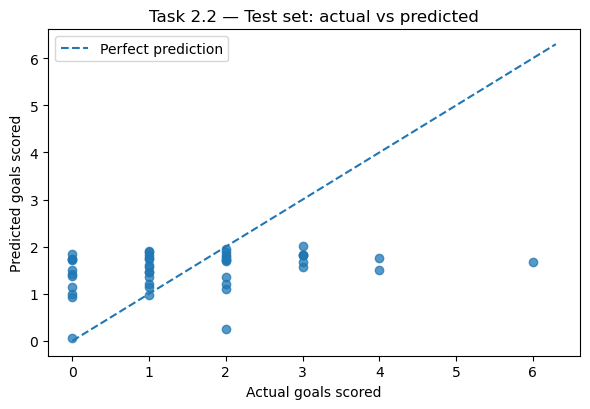

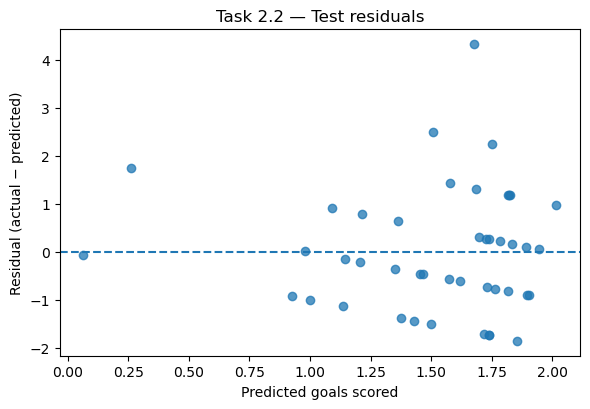

In [7]:
fig, ax = plt.subplots(figsize=(6.0, 4.2))
ax.scatter(test["goals_scored"], test_pred, alpha=0.75)
lim_lo = min(0.0, float(np.min(test_pred)), float(test["goals_scored"].min()))
lim_hi = max(float(np.max(test_pred)), float(test["goals_scored"].max())) + 0.3
ax.plot([lim_lo,lim_hi],[lim_lo,lim_hi], linestyle="--", label="Perfect prediction")
ax.set(xlabel="Actual goals scored", ylabel="Predicted goals scored", title="Task 2.2 — Test set: actual vs predicted")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "Actual_vs_Predicted.png", dpi=160)
plt.show()

fig, ax = plt.subplots(figsize=(6.0, 4.2))
ax.scatter(test_pred, y_test.to_numpy() - test_pred, alpha=0.75)
ax.axhline(0, linestyle="--")
ax.set(xlabel="Predicted goals scored", ylabel="Residual (actual − predicted)", title="Task 2.2 — Test residuals")
fig.tight_layout()
fig.savefig(OUT / "Test_Residuals.png", dpi=160)
plt.show()


## 8. Save 208-row dataset, predictions, fitted model and settings

In [8]:
dataset_cols = ["match_id", "match_date", "team", "opponent", "side", "stage"] + FEATURES + [TARGET]
team_data[dataset_cols].to_csv(DATASET_FILE, index=False)
team_data[dataset_cols + ["data_split", "predicted_goals"]].to_csv(OUT / "Predictions.csv", index=False)
coefficients.to_csv(OUT / "Coefficients.csv", index=False)
pd.DataFrame({"metric": list(metrics.keys()), "value": list(metrics.values())}).to_csv(OUT / "Metrics.csv", index=False)
dump(model, OUT / "Trained_Model.joblib")
settings = {
    "task": "Linear Regression 2.2 — team goals scored",
    "estimator": "sklearn.linear_model.LinearRegression(fit_intercept=True)",
    "features": FEATURES,
    "target": TARGET,
    "shared_2_1_concepts": FEATURES[:4],
    "new_2_2_features": FEATURES[4:],
    "match_count": 104,
    "team_row_count": 208,
    "training_rows": int(len(train)),
    "testing_rows": int(len(test)),
    "training_matches": int(train["match_id"].nunique()),
    "testing_matches": int(test["match_id"].nunique()),
    "first_test_date": test_start.strftime("%Y-%m-%d"),
    "intercept": intercept,
    "notes": [
        "Stage is known before kickoff; is_knockout is therefore pre-match.",
        "World Cup cumulative histories include only matches from earlier dates.",
        "FIFA/ Elo/ previous-five-match data are reused from the source workbook and require source verification.",
        "Penalty shootout goals are not included in the original master goal totals.",
        "Match-based date split keeps both team observations for each match together.",
        "This ordinary linear regression can output negative goal predictions; interpret with caution."
    ],
    "metrics": metrics,
}
(OUT / "Model_Settings.json").write_text(json.dumps(settings, indent=2), encoding="utf-8")
print("Saved 208-row dataset at:", DATASET_FILE.resolve())
print("Saved model and outputs in:", OUT.resolve())
print("Files:")
for p in sorted(OUT.iterdir()): print("  ", p.name)


Saved 208-row dataset at: C:\Users\arysh\Downloads\Regression_2_2_Final\Regression_2_2_Final\data\Regression_2_2_208_Team_Rows.csv
Saved model and outputs in: C:\Users\arysh\Downloads\Regression_2_2_Final\Regression_2_2_Final\outputs
Files:
   Actual_vs_Predicted.png
   Coefficients.csv
   Metrics.csv
   Model_Settings.json
   Predictions.csv
   Test_Residuals.png
   Trained_Model.joblib
